# Phase 1: Exploratory Data Analysis (EDA) - Indian Equities

**Northgate AI Stock Predictor**  
*Educational purpose only, not financial advice.*

This notebook explores 5 years of daily OHLCV market data for 5 prominent Indian stocks:
- **RELIANCE.NS** (Reliance Industries Ltd. - Energy & Conglomerate)
- **TCS.NS** (Tata Consultancy Services Ltd. - IT Services)
- **INFY.NS** (Infosys Ltd. - IT Services)
- **HDFCBANK.NS** (HDFC Bank Ltd. - Banking & Financial Services)
- **ITC.NS** (ITC Ltd. - FMCG & Diversified)

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import DEFAULT_TICKERS, load_raw_data

# Visual styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

print(f'Project root: {ROOT_DIR}')
print(f'Target tickers: {DEFAULT_TICKERS}')

Project root: C:\Users\Mohnish Sahu\OneDrive\Desktop\Northgate-AI-Stock-Predicto\Northgate-AI-Stock-Predictor
Target tickers: ['RELIANCE.NS', 'TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ITC.NS']


## 1. Load Raw Datasets
Loading saved 5-year OHLCV CSVs from `data/raw/` for each ticker.

In [2]:
data_dir = ROOT_DIR / 'data' / 'raw'
dfs = {}

for ticker in DEFAULT_TICKERS:
    df = load_raw_data(ticker, input_dir=data_dir)
    dfs[ticker] = df
    print(f'{ticker:<12}: {len(df)} rows | {df.index.min().strftime("%Y-%m-%d")} to {df.index.max().strftime("%Y-%m-%d")}')

RELIANCE.NS : 1237 rows | 2021-11-08 to 2026-11-06
TCS.NS      : 1237 rows | 2021-11-08 to 2026-11-06
INFY.NS     : 1237 rows | 2021-11-08 to 2026-11-06


HDFCBANK.NS : 1237 rows | 2021-11-08 to 2026-11-06
ITC.NS      : 1237 rows | 2021-11-08 to 2026-11-06


## 2. Summary Statistics & Data Inspection
Inspect columns, missing values, and calculate summary metrics.

In [3]:
# Combine Close prices into a single DataFrame
close_df = pd.DataFrame({ticker: dfs[ticker]['Close'] for ticker in DEFAULT_TICKERS}).dropna()

# Combine Daily Returns into a single DataFrame
returns_df = pd.DataFrame({ticker: dfs[ticker]['Daily_Return'] for ticker in DEFAULT_TICKERS}).dropna()

print('--- Summary Statistics: Close Prices (INR) ---')
display(close_df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

print('\n--- Summary Statistics: Daily Returns (% p.d.) ---')
display((returns_df * 100).describe().T[['mean', 'std', 'min', '50%', 'max']])

--- Summary Statistics: Close Prices (INR) ---


,count,mean,std,min,50%,max
RELIANCE.NS,1237.0,1288.496366,140.114535,1015.876526,1270.800049,1600.900024
TCS.NS,1237.0,3377.368427,564.987046,1982.599976,3390.399902,4553.750000
INFY.NS,1237.0,1524.405094,225.834055,985.299988,1511.349976,1999.699951
HDFCBANK.NS,1237.0,815.013501,91.769459,640.650024,804.799988,1012.900024
ITC.NS,1237.0,364.420133,78.799843,200.767822,400.750000,503.363953



--- Summary Statistics: Daily Returns (% p.d.) ---


,mean,std,min,50%,max
RELIANCE.NS,0.021190,1.443730,-7.485139,0.024733,11.597560
TCS.NS,-0.016926,1.441760,-8.386120,-0.053546,6.790591
INFY.NS,-0.017297,1.664680,-9.422683,-0.037902,7.934015
HDFCBANK.NS,0.007773,1.340064,-8.435817,0.009193,10.013283
ITC.NS,0.027931,1.264068,-9.714639,0.000000,5.497800


## 3. Historical Price Trends
Plotting the 5-year closing price history for each individual stock.

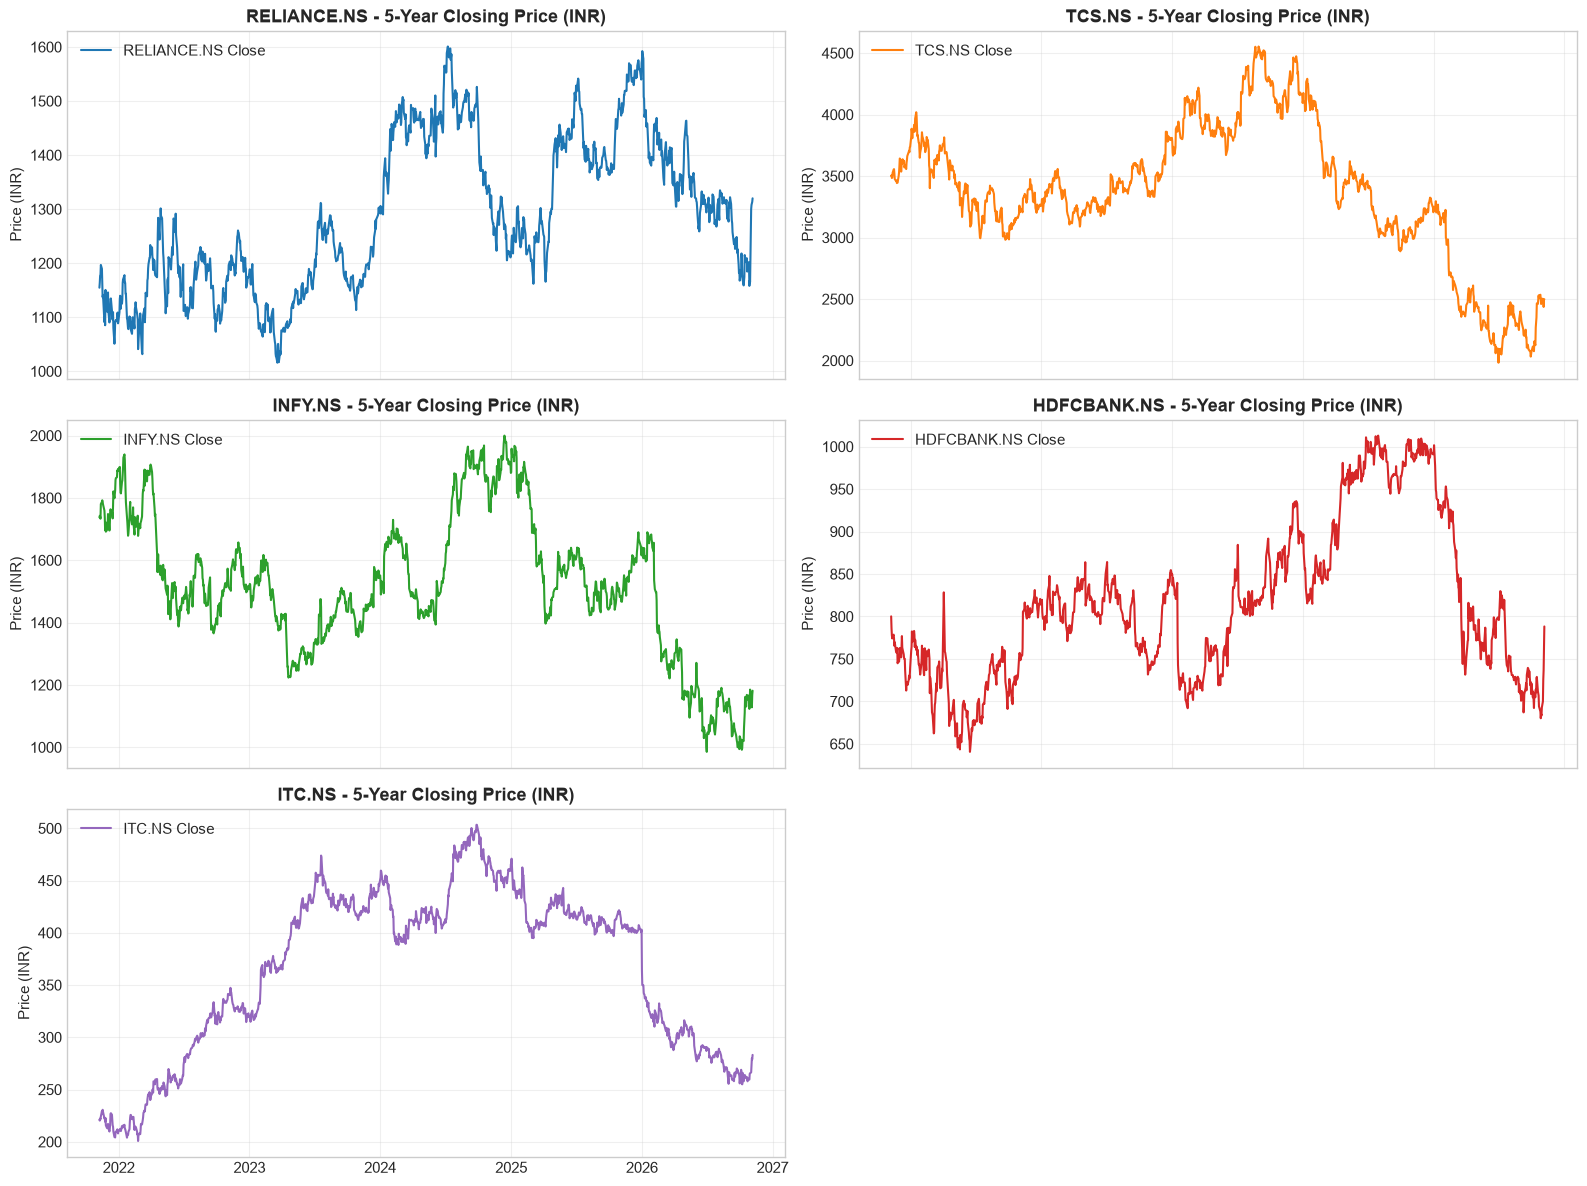

In [4]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for i, ticker in enumerate(DEFAULT_TICKERS):
    ax = axes[i]
    ax.plot(close_df.index, close_df[ticker], label=f'{ticker} Close', color=f'C{i}', linewidth=1.5)
    ax.set_title(f'{ticker} - 5-Year Closing Price (INR)', fontweight='bold')
    ax.set_ylabel('Price (INR)')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

# Remove the unused 6th subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

## 4. Normalized Growth Comparison (Base = 100)
Comparing relative cumulative growth of all 5 stocks over the 5-year period.

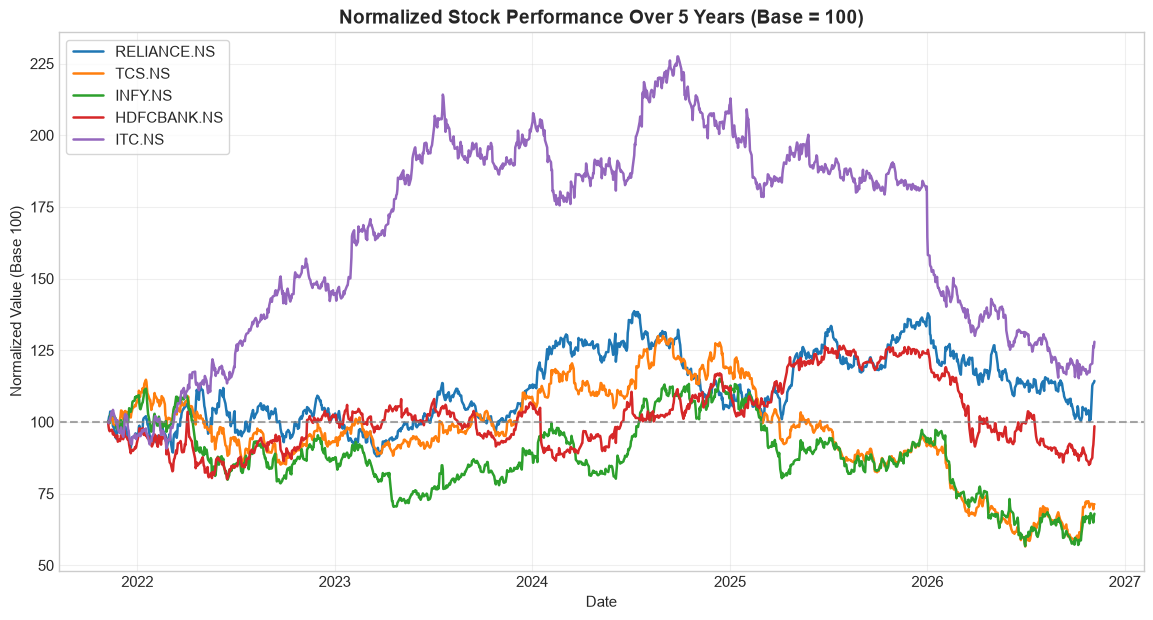

In [5]:
normalized_df = (close_df / close_df.iloc[0]) * 100

plt.figure(figsize=(14, 7))
for ticker in DEFAULT_TICKERS:
    plt.plot(normalized_df.index, normalized_df[ticker], label=ticker, linewidth=1.8)

plt.title('Normalized Stock Performance Over 5 Years (Base = 100)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Normalized Value (Base 100)')
plt.axhline(100, color='gray', linestyle='--', alpha=0.7)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, alpha=0.3)
plt.show()

## 5. Daily Return Distributions & Annualized Volatility
Examining return distribution shapes and annualized volatility (assuming 252 trading days/year).

--- Risk & Return Profiles (Annualized) ---


,Annualized Return (%),Annualized Volatility (%),Sharpe Ratio (Rf=6%)
RELIANCE.NS,5.48,22.92,-0.02
TCS.NS,-4.18,22.89,-0.44
INFY.NS,-4.27,26.43,-0.39
HDFCBANK.NS,1.98,21.27,-0.19
ITC.NS,7.29,20.07,0.06


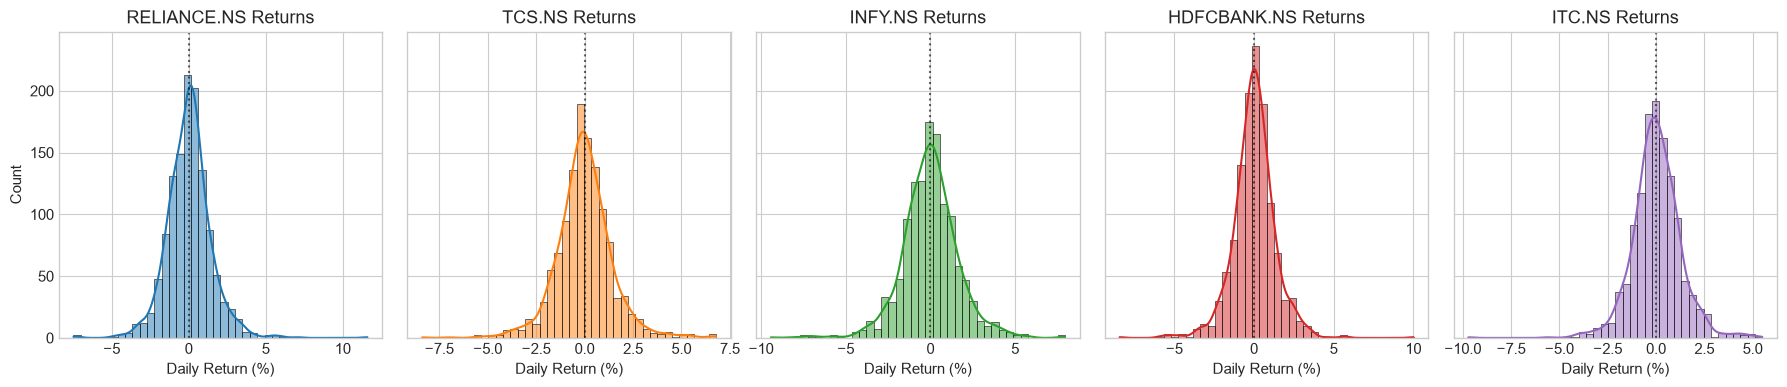

In [6]:
annualized_vol = returns_df.std() * np.sqrt(252) * 100
annualized_ret = ((1 + returns_df.mean()) ** 252 - 1) * 100

risk_return_df = pd.DataFrame({
    'Annualized Return (%)': annualized_ret.round(2),
    'Annualized Volatility (%)': annualized_vol.round(2),
    'Sharpe Ratio (Rf=6%)': ((annualized_ret - 6.0) / annualized_vol).round(2)
})

print('--- Risk & Return Profiles (Annualized) ---')
display(risk_return_df)

# Plot Return Histograms
fig, axes = plt.subplots(1, len(DEFAULT_TICKERS), figsize=(18, 4), sharey=True)
for i, ticker in enumerate(DEFAULT_TICKERS):
    sns.histplot(returns_df[ticker] * 100, kde=True, ax=axes[i], color=f'C{i}', bins=40)
    axes[i].set_title(f'{ticker} Returns')
    axes[i].set_xlabel('Daily Return (%)')
    axes[i].axvline(0, color='black', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Correlation Matrix
Analyzing pairwise correlation between stock returns for portfolio diversification insights.

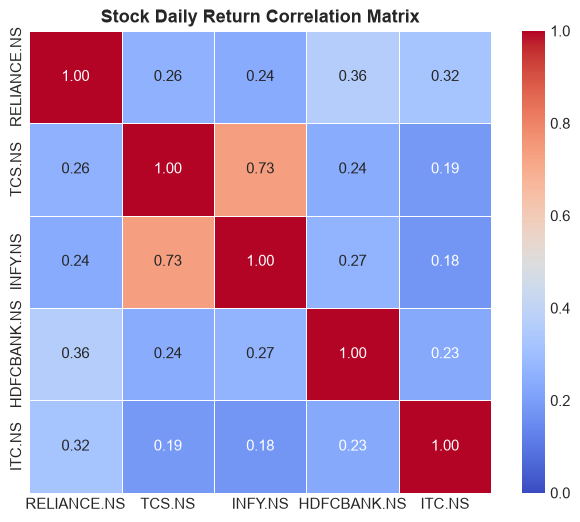

In [7]:
plt.figure(figsize=(8, 6))
corr = returns_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0, vmax=1, fmt='.2f', square=True, linewidths=0.5)
plt.title('Stock Daily Return Correlation Matrix', fontsize=13, fontweight='bold')
plt.show()

## 7. Trading Volume Trends (30-Day Rolling Average)
Examining liquidity and market activity trends.

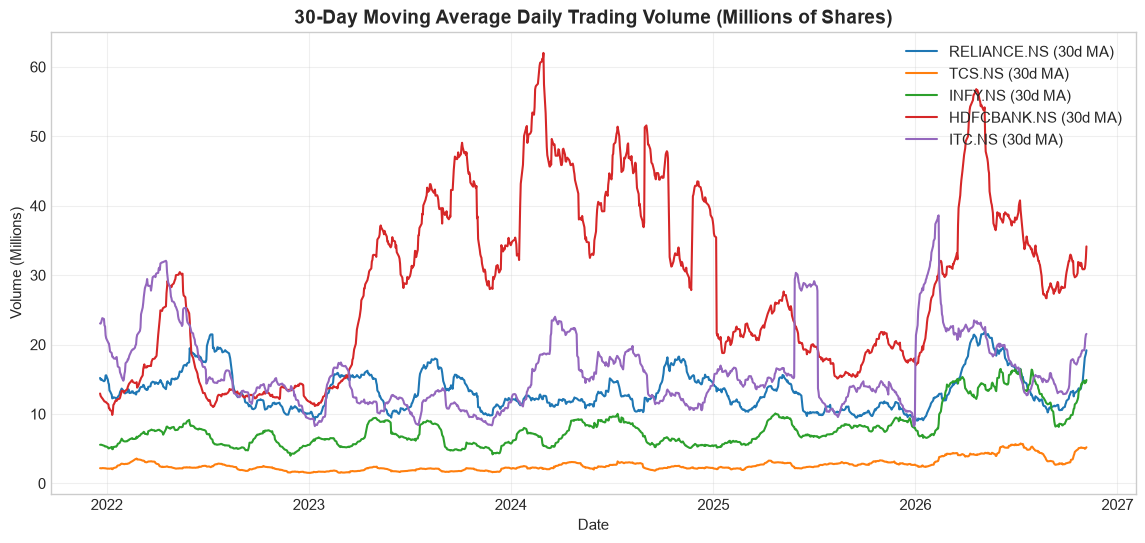

In [8]:
plt.figure(figsize=(14, 6))
for i, ticker in enumerate(DEFAULT_TICKERS):
    rolling_vol = dfs[ticker]['Volume'].rolling(window=30).mean() / 1e6
    plt.plot(rolling_vol.index, rolling_vol, label=f'{ticker} (30d MA)', linewidth=1.5)

plt.title('30-Day Moving Average Daily Trading Volume (Millions of Shares)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Volume (Millions)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

## 8. EDA Insights & Next Steps
- **Data Quality:** All 5 tickers have complete, continuous daily OHLCV series across 5 years (~1,237 trading days) with zero missing dates after clean handling.
- **Trend Dynamics:** Indian mega-caps display distinct cyclical behavior across sectors (Energy, IT, Banking, FMCG).
- **Correlation:** IT peers (TCS and INFY) exhibit high co-movement (~0.7+), while FMCG (ITC) and Banking (HDFCBANK) offer meaningful portfolio diversification.
- **Ready for Phase 2:** Data is ready for feature engineering (RSI, MACD, Bollinger Bands, Moving Averages, and chronological train/validation/test splits).